# Juzhen for Python: a tutorial

[Juzhen](https://github.com/anewgithubname/Juzhen) is a small C++ library of matrices and
neural networks that runs on the CPU and on GPUs (CUDA, ROCm and Apple Metal). The `juzhen`
Python package puts a numpy-like interface on top of it.

This notebook goes from matrices to training neural networks, and uses
[matplotlib](https://matplotlib.org) to look at the data and the results along the way.
It runs in a few minutes on a CPU, faster on a GPU.

**Before you start.** From the root of a clone of the repository:

```
pip install ./python                 # add -C cmake.define.NVIDIA_CUDA=ON (or ROCM_HIP, APPLE_SILICON) for a GPU
pip install matplotlib jupyter
```

Then open this notebook from the clone: the MNIST examples read the data in its `datasets/` folder.

## 1. Setup

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt

import juzhen as jz

print("GPU backend:", jz.backend(), "| has a GPU:", jz.has_gpu())
device = "gpu" if jz.has_gpu() else "cpu"   # used throughout; set it to "cpu" to compare

jz.manual_seed(0)                          # makes juzhen's random numbers repeatable
rng = np.random.default_rng(0)             # numpy's, for data we make ourselves

GPU backend: rocm | has a GPU: True


## 2. Matrices

A juzhen matrix is a two-dimensional float32 matrix. Like numpy, and like most machine learning
code, data is **one sample per row**: 1000 points in the plane are a 1000 x 2 matrix.

`jz.array` copies a list or a numpy array into a new matrix:

In [2]:
A = jz.array([[1, 2, 3],
              [4, 5, 6]])
print(A.shape, A.device)
A

(2, 3) cpu


Matrix([[1., 2., 3.],
        [4., 5., 6.]], device='cpu')

Other shapes are turned into two dimensions: a vector of length N becomes N x 1 (one value per
sample), and images N x C x H x W become N x (C·H·W), which is what the convolution layers expect.

In [3]:
print(jz.array(np.arange(4)).shape)
print(jz.array(np.zeros((10, 1, 28, 28))).shape)

(4, 1)
(10, 784)


Matrices can also be made directly, on either device:

In [4]:
print(jz.zeros(2, 3))
print(jz.ones(2, 3, device=device))
R = jz.randn(1000, 2, device=device)   # standard normal
U = jz.rand(1000, 1, device=device)    # uniform on [0, 1)

Matrix([[0., 0., 0.],
        [0., 0., 0.]], device='cpu')


Matrix([[1., 1., 1.],
        [1., 1., 1.]], device='gpu')

## 3. Juzhen and matplotlib

There are two ways to hand a matrix to numpy or matplotlib:

* **Directly.** Matrices support numpy's array protocol, so `plt.plot(x, y)`, `plt.scatter`,
  `plt.imshow` and numpy functions such as `np.mean` accept them as they are.
* **With `.numpy()`**, which returns a numpy copy. Use it when you need to reshape or flatten
  first: a histogram wants a 1-D array, an image of a digit wants 28 x 28.

Both copy the data out of Juzhen (from the GPU, if it is there) and wait for the GPU to finish,
so convert for plotting and reporting, not inside a fast loop.

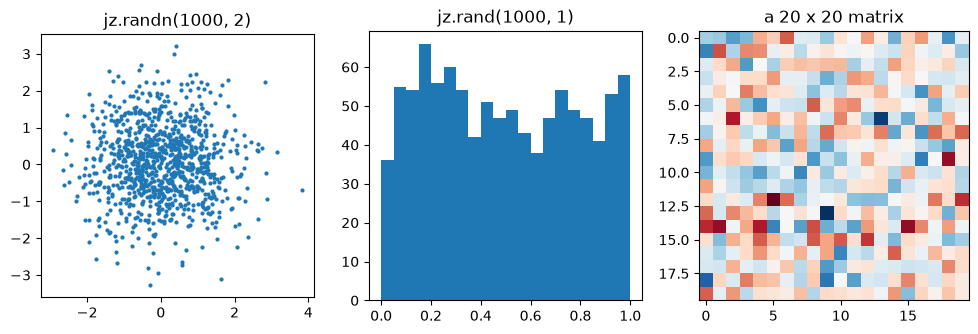

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].scatter(R[:, 0], R[:, 1], s=4)          # matrices straight into matplotlib
axes[0].set_title("jz.randn(1000, 2)")
axes[0].set_aspect("equal")

axes[1].hist(U.numpy().ravel(), bins=20)         # .numpy(), then flatten for a histogram
axes[1].set_title("jz.rand(1000, 1)")

axes[2].imshow(jz.randn(20, 20), cmap="RdBu")    # a matrix as an image
axes[2].set_title("a 20 x 20 matrix")
plt.show()

## 4. Arithmetic

`@` is the matrix product and `*` is the elementwise product, as in numpy.

In [6]:
B = jz.array([[.1, .2],
              [.3, .4],
              [.5, .6]])
print(A @ B)       # (2 x 3) @ (3 x 2)
print(A * A)       # elementwise
print(2 * A + 1)   # with numbers
print(A.T)         # the transpose shares the data: no copy

Matrix([[2.2      , 2.8000002],
        [4.9      , 6.4      ]], device='cpu')
Matrix([[ 1.,  4.,  9.],
        [16., 25., 36.]], device='cpu')
Matrix([[ 3.,  5.,  7.],
        [ 9., 11., 13.]], device='cpu')
Matrix([[1., 4.],
        [2., 5.],
        [3., 6.]], device='cpu')


**Broadcasting**: a 1 x c row is applied to every row, an r x 1 column to every column,
a 1 x 1 matrix to every element.

In [7]:
row = jz.array([[10, 20, 30]])     # 1 x 3
col = jz.array([[100], [200]])     # 2 x 1
print(A + row)
print(A - col)

Matrix([[11., 22., 33.],
        [14., 25., 36.]], device='cpu')
Matrix([[ -99.,  -98.,  -97.],
        [-196., -195., -194.]], device='cpu')


**In place**: `+=`, `-=`, `*=` and `/=` change a matrix without making a new one. This matters
for speed with large matrices (section 7).

In [8]:
C = jz.zeros(2, 3)
C += A
C *= 0.5
C

Matrix([[0.5, 1. , 1.5],
        [2. , 2.5, 3. ]], device='cpu')

## 5. Functions and reductions

Elementwise functions live in `jz`: `exp`, `log`, `sqrt`, `square`, `abs`, `sin`, `cos`,
`tanh`, `relu`, `sigmoid`. Here they are on 200 points, computed on the device and plotted
directly:

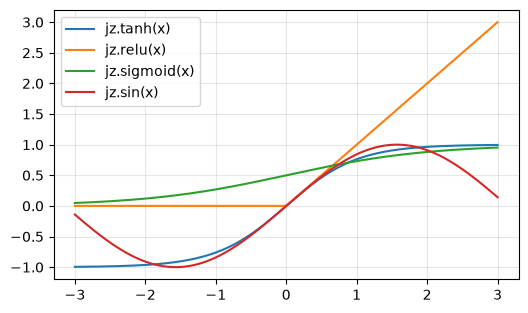

In [9]:
x = jz.array(np.linspace(-3, 3, 200), device=device)     # 200 x 1

fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ["tanh", "relu", "sigmoid", "sin"]:
    ax.plot(x, getattr(jz, name)(x), label=f"jz.{name}(x)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Reductions take an `axis`: 0 works down each column (a 1 x columns result), 1 along each row
(rows x 1), and no axis gives a 1 x 1 matrix. Results stay matrices on the device;
`.item()` turns a 1 x 1 matrix into a Python number.

In [10]:
M = jz.array(rng.standard_normal((4, 5)), device=device)
print("column sums:", jz.sum(M, 0))
print("row means:  ", jz.mean(M, 1).T)       # shown as a row
print("total:      ", jz.sum(M).item())
print("row maxima: ", jz.max(M, 1).T)
print("argmax:     ", jz.argmax(M).T)        # positions, stored as floats

column sums: Matrix([[-0.8682165 ,  0.66896206, -1.0538273 , -0.40599623, -2.0044885 ]], device='gpu')
row means:   Matrix([[ 0.04065574,  0.12870386, -0.8743364 , -0.02773653]], device='gpu')
total:       -3.6635663509368896
row maxima:  Matrix([[0.64042264, 1.304     , 0.04132598, 1.0425134 ]], device='gpu')
argmax:      Matrix([[2., 1., 1., 4.]], device='gpu')


In [11]:
scores = jz.array([[2.0, 1.0, 0.1],
                   [0.5, 2.5, 0.0]])
print(jz.softmax(scores))                    # each row sums to one
values, positions = jz.topk(scores, 2)       # the two largest of each row
print(values)
print(positions)

Matrix([[0.6590012 , 0.24243298, 0.09856589],
        [0.11116561, 0.821409  , 0.06742536]], device='cpu')
Matrix([[2. , 1. ],
        [2.5, 0.5]], device='cpu')
Matrix([[0., 1.],
        [1., 0.]], device='cpu')


## 6. Indexing and stacking

Indexing with integers, slices and lists works like numpy, but always returns a matrix, except
for a single element, which is a Python float.

In [12]:
M = jz.array(np.arange(20).reshape(4, 5))
print(M[1:3])            # rows 1 and 2
print(M[:, [0, 4]])      # columns 0 and 4
print(M[2, 3])           # one element
print(jz.hstack([M[:, :2], M[:, 3:]]).shape, jz.vstack([M, M]).shape)

Matrix([[ 5.,  6.,  7.,  8.,  9.],
        [10., 11., 12., 13., 14.]], device='cpu')
Matrix([[ 0.,  4.],
        [ 5.,  9.],
        [10., 14.],
        [15., 19.]], device='cpu')
13.0
(4, 4) (8, 5)


## 7. Devices and speed

Every matrix lives on one device. `.to("gpu")` and `.to("cpu")` make a copy on the other one;
operations need both matrices on the same device.

GPU work runs in the background: Python goes on while the GPU computes. Reading a result
(`.item()`, `.numpy()`, `print`, plotting) waits for it, and so does `jz.synchronize()`, which
you need when timing.

In [13]:
def time_product(X, repeats=5):
    X @ X                                    # warm-up
    jz.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        X @ X
    jz.synchronize()                         # wait for the GPU before stopping the clock
    return (time.perf_counter() - start) / repeats

n = 2000
X_cpu = jz.randn(n, n)
for name, X in [("cpu", X_cpu), (device, X_cpu.to(device))]:
    seconds = time_product(X)
    print(f"{name}: {seconds * 1000:6.1f} ms per {n} x {n} product = {2 * n**3 / seconds / 1e12:.2f} TFLOPS")

cpu:   29.3 ms per 2000 x 2000 product = 0.55 TFLOPS
gpu:    6.3 ms per 2000 x 2000 product = 2.53 TFLOPS


In [14]:
if jz.has_gpu():
    try:
        X_cpu + X_cpu.to("gpu")
    except Exception as error:
        print(type(error).__name__, error)

ValueError the matrices are on different devices ('cpu' and 'gpu'); move one with .to('cpu') or .to('gpu')


**A speed tip.** Every operator returns a new matrix, so `S += A1 @ A2 / n` makes `A1 @ A2`
and then a second matrix for the division. With large matrices, divide in place instead:

In [15]:
A1, A2 = jz.randn(n, n, device=device), jz.randn(n, n, device=device)
S = jz.zeros(n, n, device=device)

S += A1 @ A2 / n      # one extra n x n matrix for "/ n"

P = A1 @ A2           # the same, without it
P /= n
S += P

## 8. A first neural network

A network is a `jz.Sequential` of layers. `jz.Dense(256, activation="relu")` is a fully
connected layer with 256 outputs; `jz.Linear(10)` has no activation, for the output.
Input sizes are worked out from the data. `fit` trains with the AdamW optimizer.

MNIST has 60,000 training images of handwritten digits, 28 x 28 pixels each. `jz.datasets.mnist()`
returns them one image per row with pixels in [0, 1], and the labels as one-hot rows.

images (60000, 784) labels (60000, 10) test images (10000, 784)


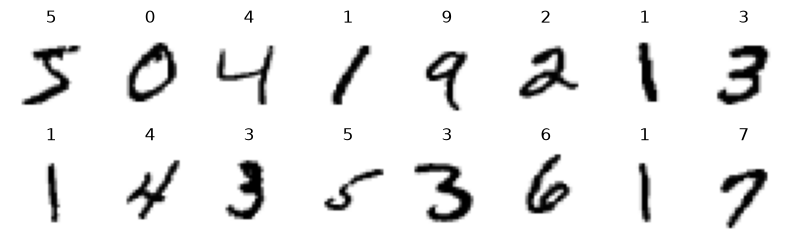

In [16]:
X, Y, X_test, Y_test = jz.datasets.mnist()
print("images", X.shape, "labels", Y.shape, "test images", X_test.shape)

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, image, label in zip(axes.flat, X[:16].numpy(), Y[:16].numpy().argmax(1)):
    ax.imshow(image.reshape(28, 28), cmap="gray_r")
    ax.set_title(int(label))
    ax.axis("off")
plt.show()

In [17]:
model = jz.Sequential(jz.Dense(256, activation="relu"), jz.Linear(10), device=device)
history = model.fit(X, Y, epochs=3, batch_size=64, lr=1e-3)
print(model.evaluate(X_test, Y_test))

epoch 1/3: loss 0.3613


epoch 2/3: loss 0.1480


epoch 3/3: loss 0.0982
{'loss': 0.09087546933442354, 'accuracy': 0.9721000373363495}


`predict` gives the scores of new images; the largest score is the predicted digit.

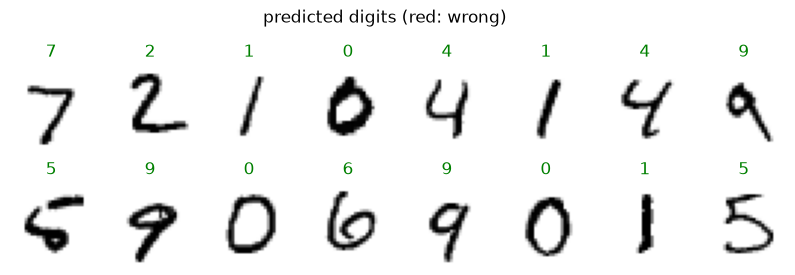

In [18]:
scores = model.predict(X_test[:16].to(device))
predicted = jz.argmax(scores).numpy().ravel().astype(int)
truth = Y_test[:16].numpy().argmax(1)

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, image, p, t in zip(axes.flat, X_test[:16].numpy(), predicted, truth):
    ax.imshow(image.reshape(28, 28), cmap="gray_r")
    ax.set_title(p, color="green" if p == t else "red")
    ax.axis("off")
fig.suptitle("predicted digits (red: wrong)", y=1.05)
plt.show()

## 9. Writing the training loop yourself

`fit` is a shortcut for the usual loop. Juzhen has no automatic differentiation: each loss
returns its value **and its gradient**, and `backward` sends that gradient back through the layers:

1. `net(X)` computes the output and keeps `X` for the backward pass;
2. `jz.nn.mse(output, target)` returns `loss.value` (1 x 1) and `loss.grad`;
3. `opt.zero_grad()`, `net.backward(loss.grad)`, `opt.step()` update the parameters.

Here a small network learns a noisy sine curve. The first layer is given its input size
(`jz.Dense(1, 64)`), so the network is built at once and the optimizer can be made before any
data has gone through it.

In [19]:
x = np.linspace(-3, 3, 512, dtype=np.float32).reshape(-1, 1)
y = np.sin(x) + 0.1 * rng.standard_normal(x.shape).astype(np.float32)
X_sin, Y_sin = jz.array(x, device=device), jz.array(y, device=device)

net = jz.Sequential(jz.Dense(1, 64), jz.Dense(64), jz.Linear(1), device=device)
opt = jz.optim.AdamW(net.parameters(), lr=1e-2, weight_decay=0)

losses = []
for step in range(1500):
    loss = jz.nn.mse(net(X_sin), Y_sin)
    opt.zero_grad()
    net.backward(loss.grad)
    opt.step()
    if step % 10 == 0:
        losses.append(loss.item())   # reading the loss waits for the GPU: not every step

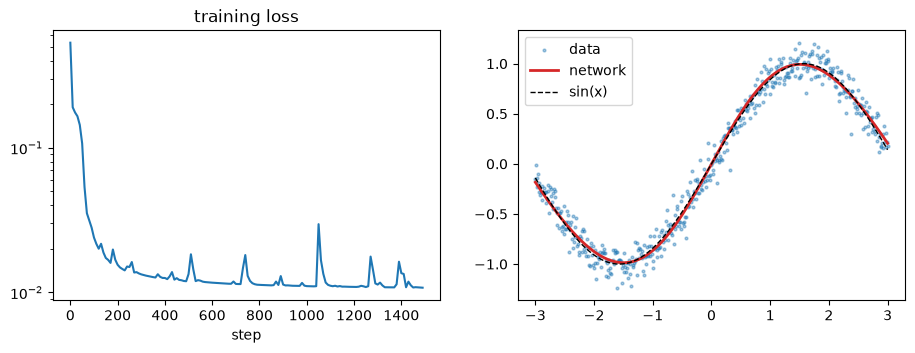

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].semilogy(np.arange(len(losses)) * 10, losses)
axes[0].set_xlabel("step")
axes[0].set_title("training loss")

axes[1].scatter(x, y, s=4, alpha=0.4, label="data")
axes[1].plot(x, net.predict(X_sin), color="C3", lw=2, label="network")
axes[1].plot(x, np.sin(x), "k--", lw=1, label="sin(x)")
axes[1].legend()
plt.show()

`net.predict(X)` is `net(X)` without keeping `X`: use it when you will not call `backward`.

## 10. Classification, parameters and a data loader

Two interleaved spirals, one per class. This section also shows the network's parameters,
a custom initialization and `jz.data.DataLoader`, which serves shuffled mini-batches.

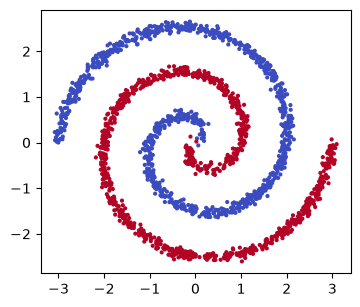

In [21]:
def spirals(n):
    t = np.sqrt(rng.random(n)) * 3 * np.pi
    label = rng.integers(0, 2, n)
    angle = t + np.pi * label
    points = np.stack([np.cos(angle), np.sin(angle)], 1) * (t / np.pi)[:, None]
    return (points + 0.06 * rng.standard_normal((n, 2))).astype(np.float32), label

points, labels = spirals(2000)
targets = jz.nn.one_hot(labels, 2)          # 2000 x 2 one-hot rows

plt.figure(figsize=(4, 4))
plt.scatter(points[:, 0], points[:, 1], c=labels, cmap="coolwarm", s=4)
plt.gca().set_aspect("equal")
plt.show()

In [22]:
def make_classifier():
    return jz.Sequential(jz.Dense(2, 64, activation="relu"),
                         jz.Dense(64, activation="relu"),
                         jz.Linear(2), device=device)

clf = make_classifier()
for p in clf.parameters():
    print(p.name, p.shape)

layer0.weight (64, 2)
layer0.bias (64, 1)
layer1.weight (64, 64)
layer1.bias (64, 1)
layer2.weight (2, 64)
layer2.bias (2, 1)


New layers start with very small weights, drawn from N(0, 0.001²) as in the C++ library.
Deep ReLU networks can get stuck there, with an output that is almost exactly zero. `assign`
sets a parameter to any value; here we use He initialization, standard for ReLU networks.

In [23]:
for p in clf.parameters():
    std = np.sqrt(2 / p.shape[1]) if p.name.endswith("weight") else 0.0
    p.assign(jz.array(std * rng.standard_normal(p.shape), device=device))

In [24]:
loader = jz.data.DataLoader(points, targets, batch_size=100, shuffle=True, device=device)
opt = jz.optim.AdamW(clf.parameters(), lr=3e-3, weight_decay=0)

for epoch in range(60):
    for X_batch, Y_batch in loader:
        loss = jz.nn.softmax_cross_entropy(clf(X_batch), Y_batch)
        opt.zero_grad()
        clf.backward(loss.grad)
        opt.step()

all_points = jz.array(points, device=device)
error = jz.nn.error_rate(clf.predict(all_points), targets.to(device)).item()
print(f"training accuracy: {100 * (1 - error):.1f}%")

training accuracy: 99.9%


To see what the network has learned, ask it about every point of a grid: one `predict` call on a
90,000 x 2 matrix. `jz.softmax` turns the scores into probabilities.

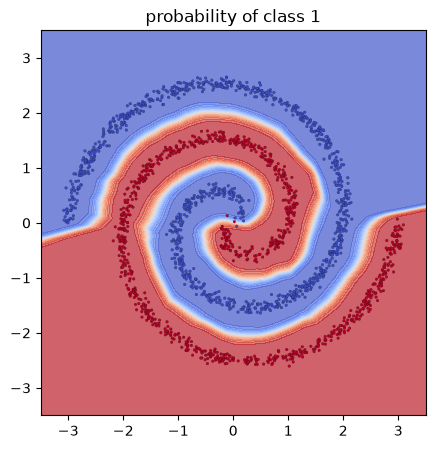

In [25]:
g = np.linspace(-3.5, 3.5, 300, dtype=np.float32)
gx, gy = np.meshgrid(g, g)
grid = jz.array(np.stack([gx.ravel(), gy.ravel()], 1), device=device)
probability = jz.softmax(clf.predict(grid))[:, 1].numpy().reshape(gx.shape)

plt.figure(figsize=(5, 5))
plt.contourf(gx, gy, probability, levels=20, cmap="coolwarm", alpha=0.7)
plt.scatter(points[:, 0], points[:, 1], c=labels, cmap="coolwarm", s=4, edgecolors="k", linewidths=0.1)
plt.title("probability of class 1")
plt.gca().set_aspect("equal")
plt.show()

## 11. Saving and moving weights

`jz.save_checkpoint` writes the parameters and the optimizer's state; `jz.load_checkpoint`
reads them into a network with the same layers. `state_dict()` returns the parameters as
numpy arrays, which `load_state_dict()` loads into another network with the same layers,
for example one on another device.

In [26]:
jz.save_checkpoint(clf, "spirals.ckpt", epoch=60)
restored = make_classifier()
print(jz.load_checkpoint(restored, "spirals.ckpt"))
print("same predictions:", np.allclose(restored.predict(grid).numpy(), clf.predict(grid).numpy()))
os.remove("spirals.ckpt")

on_cpu = jz.Sequential(jz.Dense(2, 64, activation="relu"), jz.Dense(64, activation="relu"),
                       jz.Linear(2), device="cpu")
on_cpu.load_state_dict(clf.state_dict())
print("same on the CPU:", np.allclose(on_cpu.predict(jz.array(points)).numpy(),
                                      clf.predict(all_points).numpy(), atol=1e-4))

{'epoch': 60, 'step': 0, 'data_position': 0}
same predictions: True
same on the CPU: True


## 12. Other layers

Besides `Dense` and `Linear`, `jz.nn` has `LayerNorm`, `Conv2d`, `ConvTranspose2d` and
`Transformer`. The convolution and transformer layers are made for a fixed batch size, so their
batches must all have that many rows (`DataLoader` drops a smaller last batch for this). Images
are rows of C·H·W pixels.

In [27]:
batch = 16
cnn = jz.Sequential(
    jz.nn.Conv2d(1, 8, 3, image_size=28, batch_size=batch, padding=1),             # 8 x 28 x 28
    jz.nn.Conv2d(8, 16, 3, image_size=28, batch_size=batch, padding=1, stride=2),  # 16 x 14 x 14
    jz.Linear(10),
    device=device)
print(cnn)
print("output:", cnn(X_test[:batch].to(device)).shape)

Sequential(
    Conv2d(1, 8, 3, image_size=28, batch_size=16, padding=1, stride=1, relu=True),
    Conv2d(8, 16, 3, image_size=28, batch_size=16, padding=1, stride=2, relu=True),
    Linear(10),
    device='gpu')
output: (16, 10)


## 13. Cheat sheet and next steps

| numpy | juzhen |
|---|---|
| `np.array(a, dtype=np.float32)` | `jz.array(a, device=...)` |
| `a @ b`, `a * b`, `a.T` | the same |
| `np.zeros((r, c))`, `rng.standard_normal((r, c))` | `jz.zeros(r, c)`, `jz.randn(r, c)` |
| `a.sum(axis=0, keepdims=True)` | `jz.sum(a, 0)` |
| `a.argmax(1)` | `jz.argmax(a)` (floats, rows x 1) |
| `np.hstack([a, b])` | `jz.hstack([a, b])` |
| `float(a)` for a 1 x 1 array | `a.item()` |
| (to numpy) | `a.numpy()`, or pass `a` to numpy and matplotlib directly |

The scripts in `python/examples/` go further: a convolutional network on MNIST
(`cnn_mnist.py`), a generative flow (`rectified_flow.py`), a character-level transformer language
model (`transformer_charlm.py`) and k nearest neighbours (`knn.py`).

Not there yet: automatic differentiation and layers written in Python. For now, networks are
built from the layers above.